# Laboratorio 3 - Clasificación

**Curso:** ISIS2611 - Aprendizaje de Máquina **Caso:** Ruta Alpes

**Integrantes:** Samuel Andres Molina Luna, Daniel Esteban Pardo Pardo

Ruta Alpes es una aplicación de asistencia de conducción que recomienda cupones a los conductores mientras se desplazan. Este laboratorio construye modelos de clasificación para anticipar si un conductor **aceptará** (`acepta_cupon` = Sí / No) un cupón de **Cafetería** o de **Restaurante(<20)**, y evalúa los riesgos de sesgo de personalizar ofertas con datos demográficos.

**Objetivos**
* Comparar regresión logística, árboles de decisión y Random Forest para cada tipo de cupón.
* Evaluar si el desbalance de clases afecta el desempeño y si una técnica de balanceo lo mejora.
* Reconocer posibles sesgos al usar variables demográficas para personalización.
* Comunicar los resultados y sustentar las decisiones metodológicas.

## 1. Carga de datos y librerias

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, precision_score, recall_score, f1_score

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

### Cargar datos a dataframe

In [2]:
data = pd.read_excel('data/Lab3_Datos.xlsx')
df_Base = data.copy()
df_Base.shape
df_Base.head()

,destino,acompanante,clima,temperatura,hora,cupon,vigencia_cupon,genero,edad,estado_civil,...,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,tiempo_cupon_mayor_5min,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,direccion_opuesta,acepta_cupon
0,Sin lugar urgente,Solo,Soleado,55,2:00 p.m.,Restaurante(<20),1 día,Femenino,21,Unión libre,...,nunca,NaN,4 a 8,1 a 3,Sí,No,No,No,Sí,Sí
1,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Cafetería,2 horas,Femenino,21,Unión libre,...,nunca,NaN,4 a 8,1 a 3,Sí,No,No,No,Sí,No
2,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Comida para llevar,2 horas,Femenino,21,Unión libre,...,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,Sí
3,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,2 horas,Femenino,21,Unión libre,...,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,No
4,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,1 día,Femenino,21,Unión libre,...,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,No


In [3]:
# Dataset de prueba (sin etiqueta)
df_test = pd.read_excel('data/Lab3_datos_Prueba.xlsx')
df_test.head()

,destino,acompanante,clima,temperatura,hora,cupon,vigencia_cupon,genero,edad,estado_civil,...,frecuencia_bar,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,tiempo_cupon_mayor_5min,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,direccion_opuesta
0,Trabajo,Solo,Soleado,55,7:00 a.m.,Cafetería,2 horas,Femenino,50 o más,Divorciado(a),...,1 a 3,4 a 8,4 a 8,4 a 8,menos de 1,Sí,Sí,No,No,Sí
1,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Cafetería,2 horas,Femenino,31,Unión libre,...,menos de 1,1 a 3,más de 8,4 a 8,1 a 3,Sí,No,No,No,Sí
2,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,2 horas,Femenino,31,Soltero(a),...,menos de 1,1 a 3,4 a 8,más de 8,menos de 1,Sí,Sí,No,No,Sí
3,Sin lugar urgente,Pareja,Soleado,80,10:00 a.m.,Cafetería,2 horas,Masculino,50 o más,Casado(a),...,nunca,más de 8,nunca,4 a 8,menos de 1,Sí,No,No,No,Sí
4,Sin lugar urgente,Amigo(s),Soleado,80,6:00 p.m.,Restaurante(<20),2 horas,Femenino,26,Soltero(a),...,1 a 3,menos de 1,4 a 8,menos de 1,4 a 8,Sí,Sí,No,No,Sí


# 2. Exploración de los datos

Aqui se analizan por separado los dos subconjuntos del caso que son los registros del cupon **Cafeteria** y los del cupon **Restaurante(<20)**. El objetivo es entender la variable objetivo `acepta_cupon` y diagnosticar la calidad de los datos.

**2.1 Visión general**

Se revisa el tamaño del conjunto, el tipo de dato de cada columna y un resumen estadistico para tener una primera idea de las variables.

In [4]:
print(df_Base.shape)
df_Base.dtypes

(12664, 26)


destino                              str
acompanante                          str
clima                                str
temperatura                        int64
hora                                 str
cupon                                str
vigencia_cupon                       str
genero                               str
edad                                 str
estado_civil                         str
tiene_hijos                          str
educacion                            str
ocupacion                            str
ingreso                              str
vehiculo                             str
frecuencia_bar                       str
frecuencia_cafeteria                 str
frecuencia_comida_para_llevar        str
frecuencia_restaurante_menos_20      str
frecuencia_restaurante_20_a_50       str
tiempo_cupon_mayor_5min              str
tiempo_cupon_mayor_15min             str
tiempo_cupon_mayor_25min             str
misma_direccion                      str
direccion_opuest

In [5]:
df_Base.describe(include='all')

,destino,acompanante,clima,temperatura,hora,cupon,vigencia_cupon,genero,edad,estado_civil,...,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,tiempo_cupon_mayor_5min,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,direccion_opuesta,acepta_cupon
count,12664,12664,12664,12664.000000,12664,12664,12664,12664,12664,12664,...,12447,12513,12534,12475,12664,12664,12664,12664,12664,12664
unique,3,4,3,NaN,5,5,2,2,8,5,...,5,5,5,5,1,2,2,2,2,2
top,Sin lugar urgente,Solo,Soleado,NaN,6:00 p.m.,Cafetería,1 día,Femenino,21,Casado(a),...,menos de 1,1 a 3,1 a 3,menos de 1,Sí,Sí,No,No,Sí,Sí
freq,6270,7296,10052,NaN,3224,3986,7081,6501,2652,5092,...,3378,4665,5368,6066,12664,7113,11153,9944,9944,7196
mean,NaN,NaN,NaN,63.287271,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,19.158130,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,30.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,80.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,80.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2.2 Calidad de datos y separacion por tipo de cupon y distribucion de `acepta_cupon`

El enunciado pide trabajar solo con los cupones Cafeteria y Restaurante(<20) por lo que se separa cada subconjunto y se mira cuantos registros tiene y que proporcion acepta el cupon, para saber si las clases estan balanceadas.

In [6]:
cafe = df_Base[df_Base['cupon'] == 'Cafetería'].copy()
rest = df_Base[df_Base['cupon'] == 'Restaurante(<20)'].copy()

for nombre, s in [('Cafetería', cafe), ('Restaurante(<20)', rest)]:
    print(nombre, s.shape)
    print(s['acepta_cupon'].value_counts())
    print(s['acepta_cupon'].value_counts(normalize=True).round(3), '\n')

Cafetería (3986, 26)
acepta_cupon
No    1997
Sí    1989
Name: count, dtype: int64
acepta_cupon
No    0.501
Sí    0.499
Name: proportion, dtype: float64 

Restaurante(<20) (2776, 26)
acepta_cupon
Sí    1962
No     814
Name: count, dtype: int64
acepta_cupon
Sí    0.707
No    0.293
Name: proportion, dtype: float64 



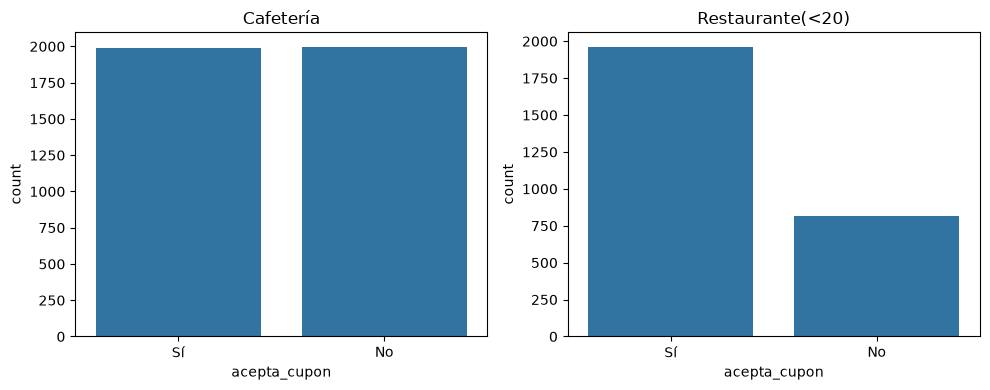

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (nombre, s) in zip(axes, [('Cafetería', cafe), ('Restaurante(<20)', rest)]):
    sns.countplot(data=s, x='acepta_cupon', order=['Sí', 'No'], ax=ax)
    ax.set_title(nombre)
plt.tight_layout()
plt.show()

Aqui analizamos lo siguiente:
- **Cafetería** (3.986 registros): las clases estan practicamente balanceadas con 1.989 "Si" que es un 49,9 % y 1.997 "No" con 50,1 %. No se necesita balanceo y la exactitud es una metrica razonable, aunque se reportaran tambien precisión, recall y F1.
- **Restaurante(<20)** (2.776 registros): hay un desbalance moderado, con 1.962 "Sí" (70,7 %) y 814 "No" (29,3 %). La clase minoritaria es "No" que son quienes rechazan el cupon.
- **Implicación para el modelado:** en Restaurante(<20), un modelo que prediga siempre "Si" obtendria 70,7 % de accuracy sin aprender nada, es por esto que la accuracy engaña y se debe evaluar con F1 y con el recall de la clase minoritaria.

**2.3 Valores nulos**

Se calcula la cantidad y el porcentaje de valores nulos por columna en cada subconjunto (Cafeteria y Restaurante(<20)).

In [10]:
nulos = pd.DataFrame({
    'Cafetería (n)': cafe.isna().sum(),
    'Cafetería (%)': (cafe.isna().mean() * 100).round(2),
    'Restaurante(<20) (n)': rest.isna().sum(),
    'Restaurante(<20) (%)': (rest.isna().mean() * 100).round(2),
})
nulos[(nulos['Cafetería (n)'] > 0) | (nulos['Restaurante(<20) (n)'] > 0)]

,Cafetería (n),Cafetería (%),Restaurante(<20) (n),Restaurante(<20) (%)
vehiculo,3949,99.07,2751,99.10
frecuencia_bar,37,0.93,23,0.83
frecuencia_cafeteria,72,1.81,47,1.69
frecuencia_comida_para_llevar,57,1.43,34,1.22
frecuencia_restaurante_menos_20,50,1.25,27,0.97
frecuencia_restaurante_20_a_50,55,1.38,43,1.55


Vemos que **`vehiculo`** tiene un 99 % de valores nulos en ambos subconjuntos (3.949 de 3.986 en Cafeteria y 2.751 de 2.776 en Restaurante(<20)). como tiene tan pocos datos no es posible imputarla de forma confiable, y en el archivo de prueba tambien esta vacia, asi que no aportaria nada al modelo. **Las cinco variables de frecuencia** tienen pocos nulos, entre 0,83 % y 1,81 %. Con esta proporcion no se justifica eliminar filas por lo que se imputaran con la moda dentro del Pipeline. Ninguna otra variable presenta valores nulos incluida la variable objetivo `acepta_cupon`, por lo que no hay registros sin etiqueta que descartar.

**2.4 Estadísticas descriptivas**

Se resumen las variables del conjunto completo (12.664 registros antes de separar por cupon). Primero la unica variable numerica `temperatura` y luego las variables categoricas, donde interesa el número de categorías (`unique`) y el valor más frecuente (`top`, `freq`).

In [17]:
df_Base.describe()

,temperatura
count,12664.000000
mean,63.287271
std,19.158130
min,30.000000
25%,55.000000
50%,80.000000
75%,80.000000
max,80.000000


In [18]:
df_Base.describe(exclude='number')

,destino,acompanante,clima,hora,cupon,vigencia_cupon,genero,edad,estado_civil,tiene_hijos,educacion,ocupacion,ingreso,vehiculo,frecuencia_bar,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,tiempo_cupon_mayor_5min,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,direccion_opuesta,acepta_cupon
count,12664,12664,12664,12664,12664,12664,12664,12664,12664,12664,12664,12664,12664,108,12557,12447,12513,12534,12475,12664,12664,12664,12664,12664,12664
unique,3,4,3,5,5,2,2,8,5,2,6,25,9,5,5,5,5,5,5,1,2,2,2,2,2
top,Sin lugar urgente,Solo,Soleado,6:00 p.m.,Cafetería,1 día,Femenino,21,Casado(a),No,Estudios universitarios sin título,Desempleado(a),$25.000 - $37.499,Scooter o motocicleta,nunca,menos de 1,1 a 3,1 a 3,menos de 1,Sí,Sí,No,No,Sí,Sí
freq,6270,7296,10052,3224,3986,7081,6501,2652,5092,7421,4344,1867,2009,22,5191,3378,4665,5368,6066,12664,7113,11153,9944,9944,7196


- **`temperatura`** es la unica variable numerica y solo toma tres valores 30, 55 y 80 °F, con media de 63,28. En la practica se comporta como una variable categorica ordenad y no como una medicion continua.
- **`vehiculo`** tiene solo 108 registros no nulos de 12.664 asi como lo vimos anteriormente.
- **`tiempo_cupon_mayor_5min`** tiene un unico valor ("Sí") en todos los registros por lo que es constante y no aporta informacion.
- **`misma_direccion` y `direccion_opuesta`** tienen la misma frecuencia en su valor mas comun que es 9.944, lo que sugiere que son complementarias.
- **`ocupacion`** tiene 25 categorias, la variable de mayor cardinalidad
- **`edad`** (8 niveles), **`ingreso`** (9) y **`educacion`** (6) son categorias con un orden natural y `hora` (5 niveles) y las variables `frecuencia_*` también lo tienen, por lo que se codificaran de forma ordinal.
- **`cupon`** tiene 5 categorias en el conjunto completo aunque en el lab se trabaja solo con Cafeteria (3.986 registros) y Restaurante(<20) (2.776).

**Duplicados**

Se revisa si existen filas completamente identicas tanto en el conjunto completo como en cada subconjunto.

In [19]:
print('Duplicados exactos en el conjunto completo:', df_Base.duplicated().sum())
for nombre, s in [('Cafetería', cafe), ('Restaurante(<20)', rest)]:
    print(f'{nombre}: {s.duplicated().sum()} de {len(s)} filas ({s.duplicated().mean()*100:.2f} %)')

Duplicados exactos en el conjunto completo: 74
Cafetería: 7 de 3986 filas (0.18 %)
Restaurante(<20): 7 de 2776 filas (0.25 %)


El conjunto completo tiene 74 filas duplicadas exactas. En cada subconjunto hay 7 lo cual es una proporcion muy pequeña, tambien los datos no incluyen un identificador de registro por lo que no es posible saber si un duplicado es una copia accidental o dos conductores distintos con exactamente las mismas respuestas. Como el efecto sobre el tamaño del conjunto es minimo y se evita el riesgo de fuga entre entrenamiento y prueba se eliminaran en la etapa de preparacion.

**2.6 Relación de las variables explicativas con `acepta_cupon`**

Para identificar qué variables parecen mas relacionadas con la aceptación del cupon se cruza cada variable con `acepta_cupon` mediante tablas de contingencia normalizadas por fila. Asi se obtiene para cada categoria el porcentaje de conductores que aceptan y que rechazan lo cual permite comparar categorias aunque tengan distinto numero de registros. Se hace por separado en Cafeteria y en Restaurante(<20). Se revisan por grupos: contexto del viaje, perfil del conductor y habitos de consumo.

In [25]:
orden_hora = ['7:00 a.m.', '10:00 a.m.', '2:00 p.m.', '6:00 p.m.', '10:00 p.m.']

for col in ['destino', 'acompanante', 'clima', 'hora', 'vigencia_cupon']:
    for nombre, s in [('Cafetería', cafe), ('Restaurante(<20)', rest)]:
        tabla = pd.crosstab(s[col], s['acepta_cupon'], normalize='index')
        if col == 'hora':
            tabla = tabla.reindex(orden_hora)
        print(f'{col} - {nombre}')
        print(tabla.round(2), '\n')

destino - Cafetería
acepta_cupon         No    Sí
destino                      
Casa               0.64  0.36
Sin lugar urgente  0.42  0.58
Trabajo            0.55  0.45 

destino - Restaurante(<20)
acepta_cupon         No    Sí
destino                      
Casa               0.44  0.56
Sin lugar urgente  0.21  0.79
Trabajo            0.42  0.58 

acompanante - Cafetería
acepta_cupon    No    Sí
acompanante             
Amigo(s)      0.40  0.60
Hijo(s)       0.52  0.48
Pareja        0.43  0.57
Solo          0.56  0.44 

acompanante - Restaurante(<20)
acepta_cupon    No    Sí
acompanante             
Amigo(s)      0.20  0.80
Hijo(s)       0.28  0.72
Pareja        0.23  0.77
Solo          0.36  0.64 

clima - Cafetería
acepta_cupon    No    Sí
clima                   
Lluvioso      0.48  0.52
Nevado        0.57  0.43
Soleado       0.50  0.50 

clima - Restaurante(<20)
acepta_cupon    No    Sí
clima                   
Lluvioso      0.61  0.39
Nevado        0.51  0.49
Soleado       0.23  

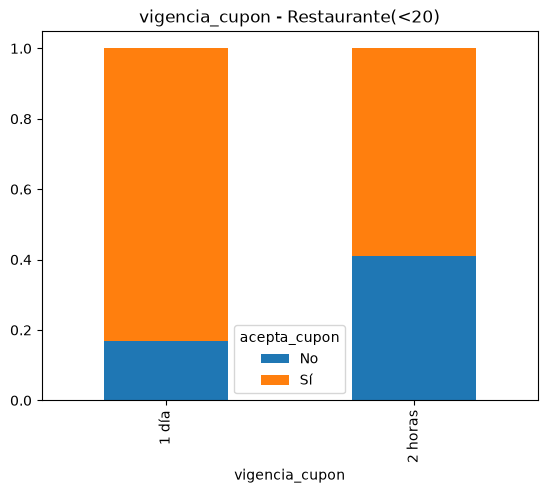

In [26]:
tabla.plot(kind='bar', stacked=True, title=f'{col} - {nombre}')
plt.show()